# 12 — Select a minimal cross-sensor swath pilot

This notebook selects one real MODIS–VIIRS candidate edge and locates the CMR granules whose time ranges and coarse granule polygons contain its source observations. It writes a two-granule sample plan only; it does not download data or confirm a shared fire. The CMR polygon is not a pixel QA/coverage mask.


In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path as PolygonPath
ROOT=Path.cwd()
if not (ROOT/'data').exists() and (ROOT.parent/'data').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.firewatch.association import find_candidate_links
OBS=ROOT/'data'/'processed'/'observations.parquet'
MANIFEST=ROOT/'data'/'reference'/'cmr_manifest_2025-10.csv'
META=MANIFEST.with_suffix('.metadata.json')
manifest_meta=json.loads(META.read_text(encoding='utf-8'))
assert hashlib.sha256(MANIFEST.read_bytes()).hexdigest()==manifest_meta['manifest_sha256']
print('Verified manifest SHA-256:',manifest_meta['manifest_sha256'])


Verified manifest SHA-256: bbf94498f5e22fb1ab9c1c614d6931e5f87ed265210bb6f054d8f3a44db373e9


In [2]:
cols=['observation_id','satellite','product_code','latitude_num','longitude_num','observation_datetime_utc','validation_status','stream_type']
obs=pd.read_parquet(OBS,columns=cols)
obs['observation_datetime_utc']=pd.to_datetime(obs.observation_datetime_utc,utc=True)
start=pd.Timestamp('2025-10-01',tz='UTC'); end=pd.Timestamp('2025-11-01',tz='UTC')
october=obs.loc[obs.observation_datetime_utc.ge(start)&obs.observation_datetime_utc.lt(end)&obs.stream_type.eq('archive')]
links=find_candidate_links(october,max_distance_km=1,max_time_delta_hours=3)
cross=links.loc[links.link_family.eq('MODIS-VIIRS')].sort_values(['time_difference_minutes','distance_km','candidate_link_id'],kind='stable')
edge=cross.iloc[0]
display(edge.to_frame('value'))
print(f'{len(cross):,} MODIS–VIIRS candidates at 1 km / 3 h; selected the shortest time separation, then shortest distance.')


,value
candidate_link_id,627beea4e144d68a848088c9471a445fc6fa70915ecddf...
left_observation_id,e7687a1ec6cf95bff149c52c686b99e4049a0562f93f8a...
right_observation_id,a233fc6b918a68d46d42f22e200d4a95d57350a33bcd70...
left_satellite,Aqua
right_satellite,SNPP
left_product_code,M-C61
right_product_code,SV-C2
left_latitude,11.0146
left_longitude,13.8575
right_latitude,11.01529


332 MODIS–VIIRS candidates at 1 km / 3 h; selected the shortest time separation, then shortest distance.


In [3]:
manifest=pd.read_csv(MANIFEST)
manifest['time_start_utc']=pd.to_datetime(manifest.time_start_utc,utc=True)
manifest['time_end_utc']=pd.to_datetime(manifest.time_end_utc,utc=True)
manifest['updated_utc']=pd.to_datetime(manifest.updated_utc,utc=True)
product_for={'Aqua':'MYD14','Terra':'MOD14','SNPP':'VNP14IMG','N20':'VJ114IMG','N21':'VJ214IMG'}
def polygon_contains(polygons_json, longitude, latitude):
    for ring_group in json.loads(polygons_json):
        values=[float(value) for value in ring_group[0].split()]
        ring=list(zip(values[::2],values[1::2]))
        if len(ring)>=3 and PolygonPath(ring).contains_point((longitude,latitude)):
            return True
    return False

plan_rows=[]
for side in ['left','right']:
    satellite=edge[f'{side}_satellite']; stamp=pd.Timestamp(edge[f'{side}_datetime_utc'])
    latitude=float(edge[f'{side}_latitude']); longitude=float(edge[f'{side}_longitude'])
    product=product_for[satellite]
    candidates=manifest.loc[manifest.short_name.eq(product)&manifest.time_start_utc.le(stamp)&manifest.time_end_utc.ge(stamp)]
    spatial=candidates.loc[candidates.spatial_polygons.map(lambda poly:polygon_contains(poly,longitude,latitude))]
    if spatial.empty: raise RuntimeError(f'No matching CMR granule for {satellite} observation {stamp}')
    # If CMR has multiple processing versions for one acquisition, choose the most recently updated for this pilot.
    selected=spatial.sort_values('updated_utc').iloc[-1]
    plan_rows.append({'candidate_link_id':edge.candidate_link_id,'edge_distance_km':edge.distance_km,
        'edge_time_difference_minutes':edge.time_difference_minutes,'observation_side':side,
        'observation_id':edge[f'{side}_observation_id'],'satellite':satellite,'product_code':edge[f'{side}_product_code'],
        'observation_time_utc':stamp.isoformat(),'observation_latitude':latitude,'observation_longitude':longitude,
        'short_name':selected.short_name,'collection_version':selected.collection_version,
        'cmr_entry_id':selected.cmr_entry_id,'producer_granule_id':selected.producer_granule_id,
        'acquisition_id':selected.acquisition_id,'granule_start_utc':selected.time_start_utc.isoformat(),
        'granule_end_utc':selected.time_end_utc.isoformat(),'updated_utc':selected.updated_utc.isoformat(),
        'granule_size_cmr_mb':selected.granule_size_cmr_mb,'data_url':selected.data_url,'browse_url':selected.browse_url,
        'spatial_polygons':selected.spatial_polygons})
plan=pd.DataFrame(plan_rows)
display(plan.drop(columns=['spatial_polygons']).T.rename(columns={0:'observation A',1:'observation B'}))


,observation A,observation B
candidate_link_id,627beea4e144d68a848088c9471a445fc6fa70915ecddf...,627beea4e144d68a848088c9471a445fc6fa70915ecddf...
edge_distance_km,0.555424,0.555424
edge_time_difference_minutes,16.0,16.0
observation_side,left,right
observation_id,e7687a1ec6cf95bff149c52c686b99e4049a0562f93f8a...,a233fc6b918a68d46d42f22e200d4a95d57350a33bcd70...
satellite,Aqua,SNPP
product_code,M-C61,SV-C2
observation_time_utc,2025-10-20T13:26:00+00:00,2025-10-20T13:10:00+00:00
observation_latitude,11.0146,11.01529
observation_longitude,13.8575,13.86254


In [4]:
out=ROOT/'data'/'reference'/'cmr_sample_plan_oct2025.csv'
plan.to_csv(out,index=False)
sample_metadata={'candidate_link_id':str(edge.candidate_link_id),'max_distance_km':1,'max_time_delta_hours':3,
 'selection_rule':'minimum time difference, then minimum distance, among MODIS-VIIRS candidates',
 'source_manifest_sha256':manifest_meta['manifest_sha256'],'sample_granule_count':len(plan),
 'granule_files_downloaded':0,'warning':'A candidate edge and CMR granule metadata do not confirm a shared fire or valid pixel coverage.'}
out.with_suffix('.metadata.json').write_text(json.dumps(sample_metadata,indent=2),encoding='utf-8')
print('Wrote sample plan:',out,'| reported combined granule size (MB):',round(plan.granule_size_cmr_mb.sum(),3))


Wrote sample plan: C:\Users\ngong\Documents\NASA CHALLENGE\data\reference\cmr_sample_plan_oct2025.csv | reported combined granule size (MB): 2.727


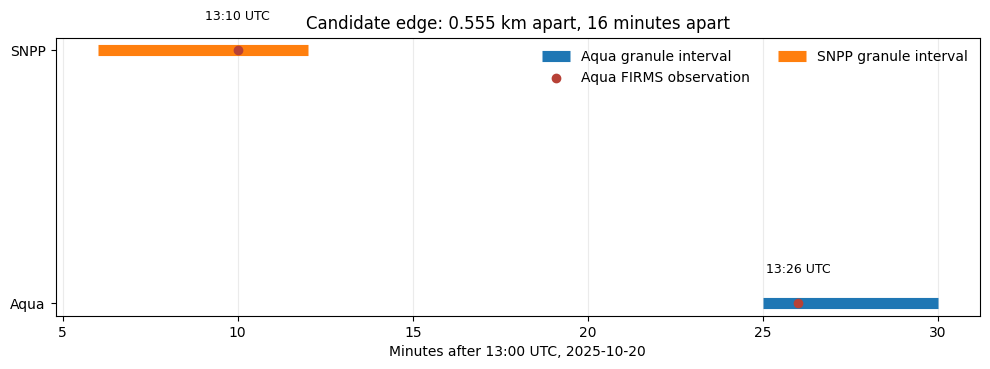

In [5]:
# Show detection timestamps relative to the two candidate granule intervals.
fig,ax=plt.subplots(figsize=(10,3.8))
for y,row in plan.iterrows():
    g0=pd.Timestamp(row.granule_start_utc); g1=pd.Timestamp(row.granule_end_utc); t=pd.Timestamp(row.observation_time_utc)
    base=pd.Timestamp('2025-10-20T13:00:00Z')
    x0=(g0-base).total_seconds()/60; x1=(g1-base).total_seconds()/60; xt=(t-base).total_seconds()/60
    ax.plot([x0,x1],[y,y],lw=8,solid_capstyle='butt',label=f'{row.satellite} granule interval')
    ax.scatter([xt],[y],color='#b74136',zorder=3,label=f'{row.satellite} FIRMS observation' if y==0 else None)
    ax.text(xt,y+0.12,t.strftime('%H:%M UTC'),ha='center',fontsize=9)
ax.set_yticks(range(len(plan)),plan.satellite); ax.set_xlabel('Minutes after 13:00 UTC, 2025-10-20')
ax.set_title(f'Candidate edge: {edge.distance_km:.3f} km apart, {edge.time_difference_minutes:.0f} minutes apart')
ax.grid(axis='x',alpha=.25); ax.legend(frameon=False,ncol=2); fig.tight_layout(); plt.show()


## Pilot limits and next action

The two selected products are Aqua MODIS MYD14 (HDF4) and Suomi-NPP VIIRS VNP14IMG (NetCDF4/HDF5). Their CMR granule intervals contain the FIRMS times and their catalog polygons contain the observation centers. The VIIRS product can be structurally inspected with the available `h5py`; MODIS requires installing/configuring an HDF4 reader (`pyhdf` or GDAL). The science data URLs are protected. After Earthdata access is configured, download only these two granules to a staging directory, verify sizes/checksums where available, and confirm both CSV detections map to a fire pixel in their own source product before attempting mask alignment.

That source-pixel reconciliation checks data lineage. The pair still remains an unvalidated association: a shared fire claim needs common valid coverage and an independent reference.
